In [ ]:
from google.colab import files
uploaded = files.upload()

Saving netflix_cleaned.csv to netflix_cleaned.csv


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned Netflix dataset
df = pd.read_csv("netflix_cleaned.csv")

# Display basic information
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nContent type counts:")
print(df["type"].value_counts())


Dataset shape: (8807, 14)

First five rows:
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water          Unknown   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans          Unknown   
4      s5  TV Show           Kota Factory          Unknown   

                                                cast        country  \
0                                            Unknown  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...        Unknown   
3                                            Unknown        Unknown   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

   date_added  release_year rating   duration  \
0  2021-09-25          2020  PG-13     90 min   
1  2021-09-24          2021  TV-MA  2 Seasons   
2  2021-0

### TV Shows

Average seasons: 1.76
Median seasons: 1.0
Most common number of seasons:
seasons
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
Name: count, dtype: int64


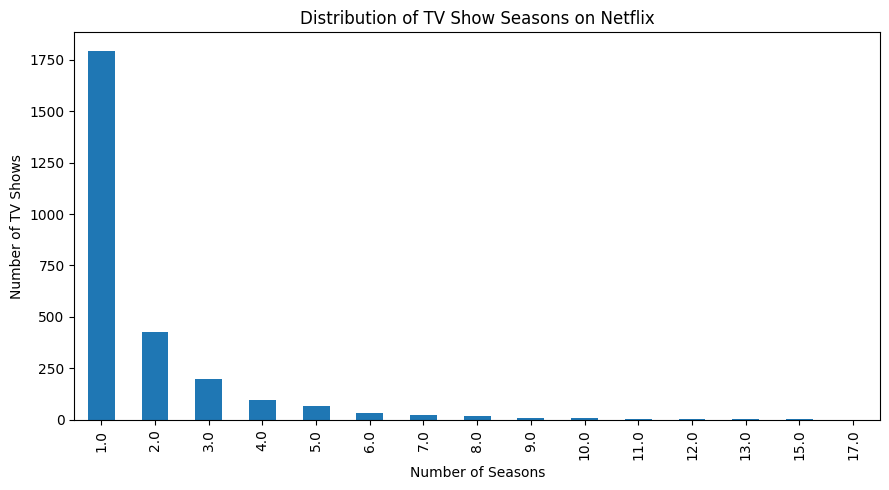

In [ ]:


# TV Show Seasons Analysis

tv_shows = df[df["type"] == "TV Show"].copy()

seasons = tv_shows["seasons"].dropna()

print("Average seasons:", round(seasons.mean(), 2))
print("Median seasons:", seasons.median())
print("Most common number of seasons:")
print(seasons.value_counts().head(10))

seasons.value_counts().sort_index().plot(
    kind="bar", figsize=(9, 5))

plt.title("Distribution of TV Show Seasons on Netflix")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.tight_layout()
plt.show()


###Histogram of movie durations

Average movie duration: 99.56 minutes
Shortest movie: 3.0 minutes
Longest movie: 312.0 minutes


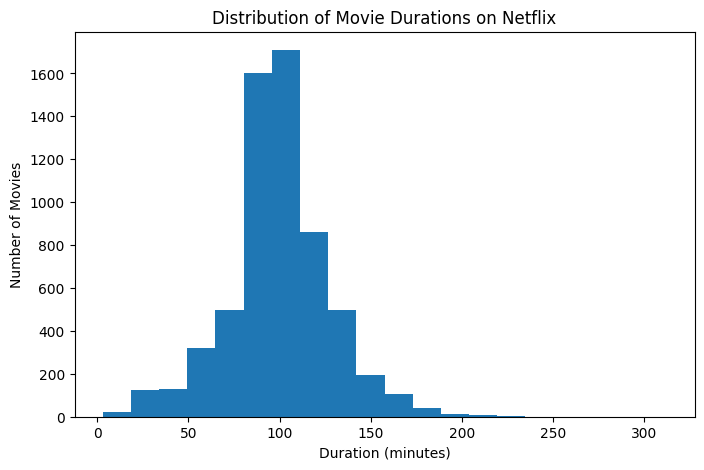

In [ ]:

# Select Movies only
movies = df[df["type"] == "Movie"]

# Display duration statistics
print("Average movie duration:", movies["duration_min"].mean().round(2), "minutes")
print("Shortest movie:", movies["duration_min"].min(), "minutes")
print("Longest movie:", movies["duration_min"].max(), "minutes")

# Create a histogram
plt.figure(figsize=(8, 5))
plt.hist(movies["duration_min"].dropna(), bins=20)

plt.title("Distribution of Movie Durations on Netflix")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.show()


###Content Ratings: Movies vs TV Shows

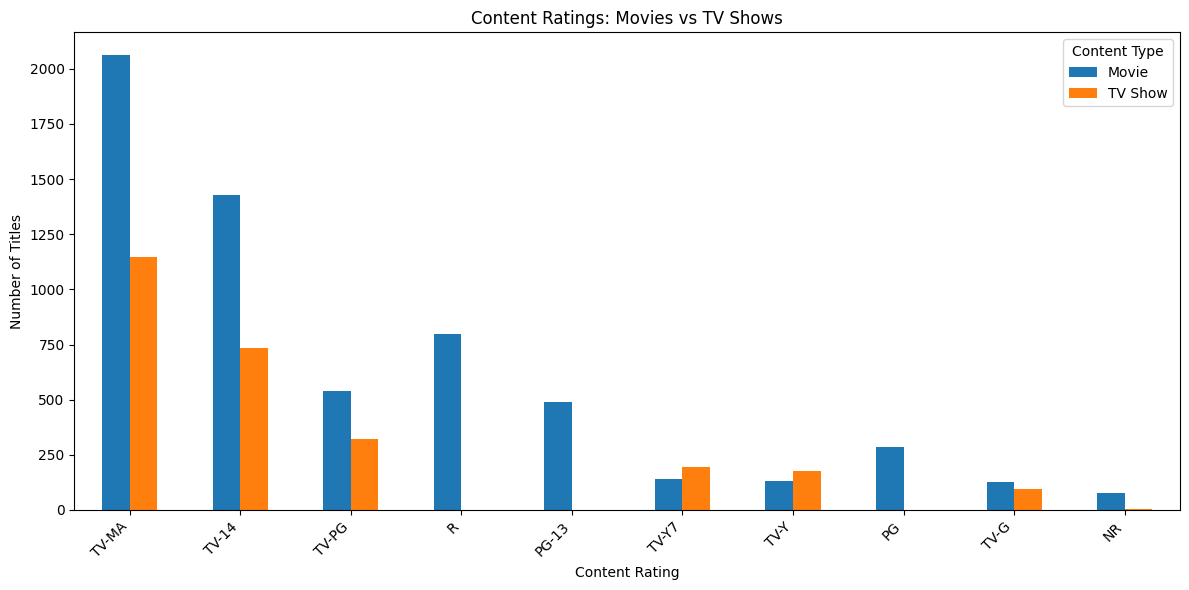

In [ ]:

# Count ratings for Movies and TV Shows
rating_data = df.dropna(subset=["rating"])

rating_comparison = rating_data.groupby(
    ["rating", "type"]).size().unstack(fill_value=0)

# Select the 10 most common ratings overall
top_ratings = rating_comparison.sum(axis=1).nlargest(10).index
rating_comparison = rating_comparison.loc[top_ratings]

# Plot both content types on the same graph
rating_comparison.plot(kind="bar", figsize=(12, 6))

plt.title("Content Ratings: Movies vs TV Shows")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


### Months which has the  most content added to Netflix

Netflix Content Added by Month:
type  Movie  TV Show
Jan     546      192
Feb     382      181
Mar     529      213
Apr     550      214
May     439      193
Jun     492      236
Jul     565      262
Aug     519      236
Sep     519      251
Oct     545      215
Nov     498      207
Dec     547      266


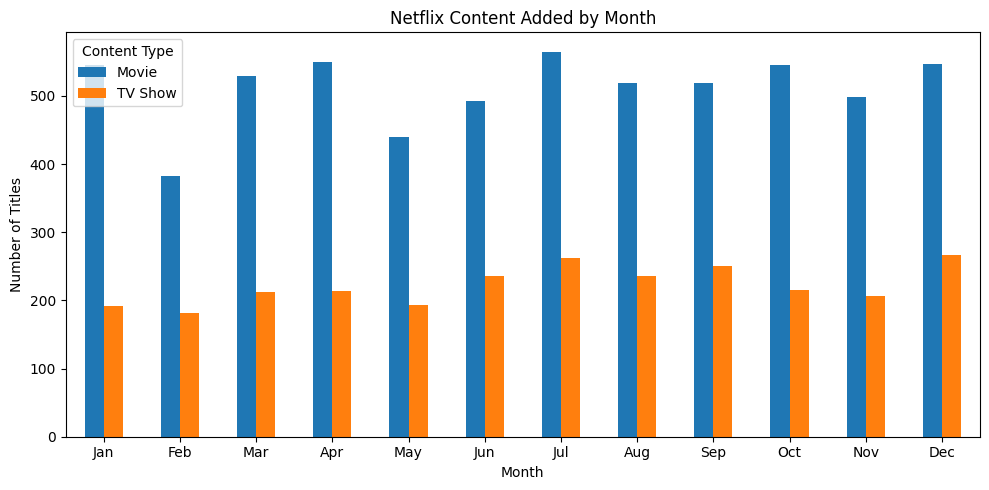

In [ ]:

# Analyse Netflix content added by month

df["date_added"] = pd.to_datetime(
    df["date_added"].astype(str).str.strip(),
    errors="coerce")

df["month_added"] = df["date_added"].dt.month

month_data = df.dropna(subset=["month_added"]).copy()

month_type = month_data.groupby(
    ["month_added", "type"]).size().unstack(fill_value=0)

month_type = month_type.reindex(range(1, 13), fill_value=0)

month_type.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

print("Netflix Content Added by Month:")
print(month_type)

month_type.plot(kind="bar", figsize=(10, 5))

plt.title("Netflix Content Added by Month")
plt.xlabel("Month")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


###Actors who appear in the most Netflix titles

Top 10 Actors with the Most Netflix Titles:
cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Takahiro Sakurai    32
Naseeruddin Shah    32
Rupa Bhimani        31
Om Puri             30
Akshay Kumar        30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64


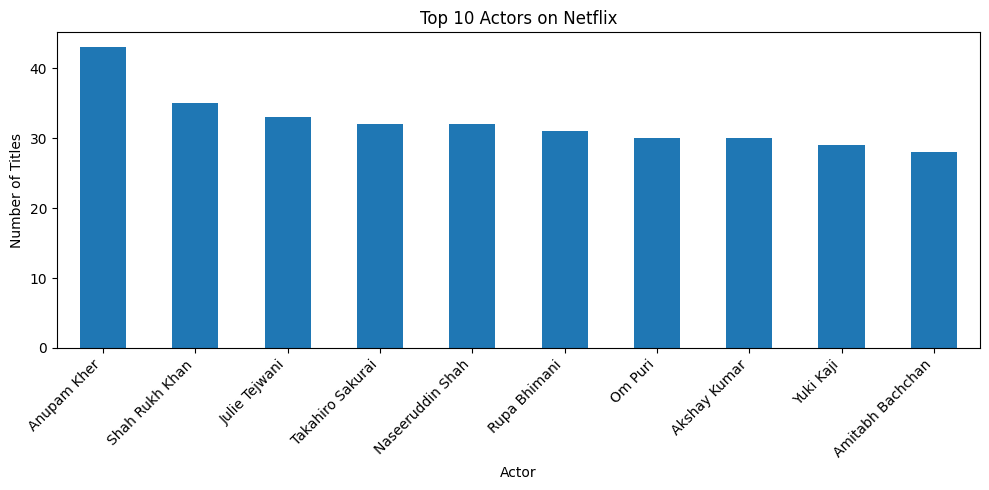

In [ ]:

cast_data = df[df["cast"].notna()].copy()

cast_data["cast"] = cast_data["cast"].str.split(", ")
cast_data = cast_data.explode("cast")

cast_data["cast"] = cast_data["cast"].str.strip()

cast_data = cast_data[ (cast_data["cast"] != "") & (cast_data["cast"].str.lower() != "unknown")]

top_actors = cast_data["cast"].value_counts().head(10)

print("Top 10 Actors with the Most Netflix Titles:")
print(top_actors)

top_actors.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Actors on Netflix")
plt.xlabel("Actor")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


###

###Content Age Classification of Netflix Movies and TV Shows

In [ ]:

# Content Age Classification

age_data = df.copy()

age_data["date_added"] = pd.to_datetime(
    age_data["date_added"].astype(str).str.strip(),
    errors="coerce")

age_data["year_added"] = age_data["date_added"].dt.year

age_data = age_data.dropna(
    subset=["release_year", "year_added"])

age_data["content_age"] = (
    age_data["year_added"] - age_data["release_year"])

age_data = age_data[age_data["content_age"] >= 0]

age_data["age_category"] = pd.cut(
    age_data["content_age"],
    bins=[-1, 2, 5, float("inf")],
    labels=["Recent (0–2 years)","Moderately Older (3–5 years)","Older (More than 5 years)"])

# Summary table with counts and percentages
summary = age_data["age_category"].value_counts().reindex(
    ["Recent (0–2 years)",
     "Moderately Older (3–5 years)",
     "Older (More than 5 years)"],
    fill_value=0).to_frame("Number of Titles")

summary["Percentage"] = ( summary["Number of Titles"] / len(age_data) * 100).round(2)

print("Content Age Classification:")
print(summary)

# Compare movies and TV shows
print("\nContent Age by Type:")
print(pd.crosstab(age_data["age_category"], age_data["type"]))


Content Age Classification:
                              Number of Titles  Percentage
age_category                                              
Recent (0–2 years)                        5540       63.08
Moderately Older (3–5 years)              1119       12.74
Older (More than 5 years)                 2124       24.18

Content Age by Type:
type                          Movie  TV Show
age_category                                
Recent (0–2 years)             3531     2009
Moderately Older (3–5 years)    811      308
Older (More than 5 years)      1787      337
